# XGBoost tuning with Optuna - objective F-beta (beta = 2)

**Goal:** improve the churn champion (`XGBoost`) with **30 Optuna trials**, but optimise what the
retention team actually needs: **catch as many churners as possible** at a usable precision.

**Why F2 and not PR-AUC.** The previous study maximised PR-AUC. That metric rewards good *ranking*
and it settled on a high cut-off (0.5223), so it flagged fewer customers and caught **299 of 407**
test churners instead of the baseline's **315 of 407**. Ranking quality went up while the number of
caught churners went down. `F-beta` with `beta = 2` scores the decision itself and weights recall
twice as much as precision, so the search now prefers models and cut-offs that flag more customers.

**This is the second study.** The first 13-parameter run produced the importance table in
section 3, so this study tunes only the **8 parameters that carry 92%** of the score and fixes
the other 5 at their winning values. Same objective (F2), same data, same 30-trial budget.

**Protocol**

- Data: `data/processed/churn_processed.csv`, stratified 80/20 split, `random_state=42`.
- Objective: mean **best-achievable F2** over 5 stratified folds. For each fold the F2 is maximised
  over all probability cut-offs, so a trial cannot win by sitting on a bad cut-off.
- Sampler: TPE with `seed=42` (reproducible).
- The test set is scored once at the end, at the cut-off learned from out-of-fold scores.
- Results are recorded in `FINDINGS.md`.

## 0. Setup

In [11]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna

from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, train_test_split
from xgboost import XGBClassifier

%matplotlib inline
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_PATH = PROJECT_ROOT / "data" / "processed" / "churn_processed.csv"

TARGET = "Exited"
SEED = 42
TEST_SIZE = 0.2
N_TRIALS = 30
N_SPLITS = 5
BETA = 2.0                     # recall counts 2x as much as precision

# results already recorded from earlier runs (used only for the comparison table)
BASELINE = {"label": "baseline XGBoost (modelling.ipynb)", "threshold": 0.4510,
            "roc_auc": 0.8620, "pr_auc": 0.7056, "recall": 0.7740, "precision": 0.4869}
PRAUC_TUNED = {"label": "previous run, PR-AUC objective", "threshold": 0.5223,
               "roc_auc": 0.8669, "pr_auc": 0.7145, "recall": 0.7346, "precision": 0.5368}

optuna.logging.set_verbosity(optuna.logging.WARNING)


def section(title: str) -> None:
    print()
    print("=" * 78)
    print(title)
    print("=" * 78)


print(f"optuna {optuna.__version__} | data: {PROCESSED_PATH.relative_to(PROJECT_ROOT)}")
print(f"objective: F{BETA:.0f} (beta={BETA}), recall weighted {BETA:.0f}x precision")

optuna 5.0.0 | data: data\processed\churn_processed.csv
objective: F2 (beta=2.0), recall weighted 2x precision


## 1. Data and split

Same protocol as `notebooks/modelling.ipynb`: the processed frame, stratified 80/20, seed 42.

In [12]:
section("1. DATA & STRATIFIED SPLIT")
processed = pd.read_csv(PROCESSED_PATH)
X = processed.drop(columns=[TARGET])
y = processed[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y
)

print(f"X_train {X_train.shape} | X_test {X_test.shape}")
print(f"churn rate: train {y_train.mean():.4%} | test {y_test.mean():.4%}")
print(f"features ({X_train.shape[1]}): {list(X_train.columns)}")


1. DATA & STRATIFIED SPLIT
X_train (8000, 14) | X_test (2000, 14)
churn rate: train 20.3750% | test 20.3500%
features (14): ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'ZeroBalance', 'Geo_France', 'Geo_Germany', 'Geo_Spain', 'Gender_Female', 'Gender_Male']


## 2. The metric: F-beta with beta = 2

F-beta mixes precision and recall into one number:

```
F_beta = (1 + beta^2) * precision * recall / (beta^2 * precision + recall)
```

- `beta = 1` gives F1, where a missed churner and a false alarm cost the same.
- `beta = 2` gives `F2`, where the recall term has weight 4 in the numerator instead of 1.
  One missed churner is as bad as four wasted calls.

Effect on the model: to raise F2 the model must flag **more** customers. Recall goes up, precision
goes down, and more real churners get caught. That is the trade the retention team asked for.

**Threshold.** F2 depends on the cut-off, so each trial's score is the **best F2 over all
cut-offs** (from its precision-recall curve). The final cut-off is then taken from the pooled
out-of-fold scores and applied unchanged to the test set.

`PR-AUC` and `ROC-AUC` are still reported, but only as diagnostics.

In [13]:
section("2. METRIC HELPERS")


def best_fbeta(y_true, proba, beta: float = BETA):
    """Highest F-beta over all cut-offs, and the cut-off that reaches it."""
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    fbeta = (1 + beta ** 2) * precision * recall / (beta ** 2 * precision + recall + 1e-12)
    idx = int(np.argmax(np.nan_to_num(fbeta)))
    threshold = float(thresholds[min(idx, len(thresholds) - 1)])
    return float(fbeta[idx]), threshold


def fbeta_from_pr(precision: float, recall: float, beta: float = BETA) -> float:
    """F-beta from a precision/recall pair (used to score the earlier runs)."""
    return (1 + beta ** 2) * precision * recall / (beta ** 2 * precision + recall)


def metrics_at(y_true, proba, threshold: float, beta: float = BETA) -> dict:
    """Full metric row for one cut-off."""
    pred = (proba >= threshold).astype(int)
    precision = precision_score(y_true, pred, zero_division=0)
    recall = recall_score(y_true, pred, zero_division=0)
    return {
        "threshold": round(float(threshold), 4),
        "flagged_%": round(pred.mean() * 100, 2),
        "recall": round(recall, 4),
        "precision": round(precision, 4),
        "f2": round(fbeta_from_pr(precision, recall, beta), 4),
        "f1": round(f1_score(y_true, pred, zero_division=0), 4),
    }


print(f"beta = {BETA}: a miss costs {BETA ** 2:.0f}x more than a false alarm")
print(f"example - precision 0.50, recall 0.80 -> F2 = {fbeta_from_pr(0.50, 0.80):.4f}")


2. METRIC HELPERS
beta = 2.0: a miss costs 4x more than a false alarm
example - precision 0.50, recall 0.80 -> F2 = 0.7143


## 3. Reduced search space - the parameters that carry 90% of the work

The 13-parameter study showed where the score comes from. fANOVA importance from that study:

| parameter | importance | cumulative |
|---|---|---|
| `learning_rate` | 0.3762 | 0.376 |
| `colsample_bytree` | 0.1684 | 0.545 |
| `scale_pos_weight` | 0.1139 | 0.659 |
| `max_depth` | 0.0891 | 0.748 |
| `min_child_weight` | 0.0689 | 0.817 |
| `reg_alpha` | 0.0480 | 0.864 |
| `subsample` | 0.0335 | 0.898 |
| `gamma` | 0.0265 | **0.924** |
| `max_delta_step` | 0.0219 | 0.946 |
| `colsample_bylevel` | 0.0194 | 0.966 |
| `reg_lambda` | 0.0155 | 0.981 |
| `colsample_bynode` | 0.0129 | 0.994 |
| `n_estimators` | 0.0057 | 1.000 |

**Eight parameters reach 92.4% of the importance** (the top seven reach 89.8%). The remaining five
are fixed at the winning trial's values, so the model keeps its quality while the search runs over
8 dimensions instead of 13. With the same 30 trials, each tuned dimension is explored about 1.6x
more densely.

| kept tuned (8) | range |
|---|---|
| `learning_rate` | 0.01 - 0.3 (log) |
| `colsample_bytree` | 0.4 - 1.0 |
| `scale_pos_weight` | 1 - 10 |
| `max_depth` | 2 - 10 |
| `min_child_weight` | 1 - 20 |
| `reg_alpha` | 1e-3 - 10 (log) |
| `subsample` | 0.5 - 1.0 |
| `gamma` | 0 - 5 |

Fixed: `n_estimators` 400, `colsample_bylevel` 0.8854, `colsample_bynode` 0.8725,
`reg_lambda` 0.0085, `max_delta_step` 7.7363.

Ranges are unchanged, so this study compares cleanly with the 13-parameter one.

In [14]:
section("3. REDUCED SEARCH SPACE + OBJECTIVE")

# Five parameters are fixed at the winning values of the 13-parameter study (trial 19).
# Together they add only 7.5% of the importance, so tuning them again wastes trials.
FIXED_PARAMS = {
    "n_estimators": 400,
    "colsample_bylevel": 0.8854,
    "colsample_bynode": 0.8725,
    "reg_lambda": 0.0085,
    "max_delta_step": 7.7363,
}

# The eight parameters that carry 92.4% of the importance. Ranges stay unchanged.
TUNED_PARAMS = ["learning_rate", "colsample_bytree", "scale_pos_weight", "max_depth",
                "min_child_weight", "reg_alpha", "subsample", "gamma"]


def suggest_params(trial) -> dict:
    """The 8 high-importance XGBoost hyperparameters for one trial."""
    return {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1.0, 10.0),
        "max_depth": trial.suggest_int("max_depth", 2, 10),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 20),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "gamma": trial.suggest_float("gamma", 0.0, 5.0),
    }


def full_params(params: dict) -> dict:
    """Tuned choices merged with the fixed parameters."""
    return {**FIXED_PARAMS, **params}


def cross_validate(params: dict, X_data, y_data, n_splits: int = N_SPLITS):
    """Mean/std best-F2 over stratified folds, the out-of-fold scores, and mean fold cut-off."""
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    oof = np.zeros(len(y_data))
    fold_scores, fold_thresholds = [], []
    for tr_idx, va_idx in cv.split(X_data, y_data):
        model = XGBClassifier(**full_params(params), tree_method="hist",
                              random_state=SEED, n_jobs=-1)
        model.fit(X_data.iloc[tr_idx], y_data.iloc[tr_idx])
        proba = model.predict_proba(X_data.iloc[va_idx])[:, 1]
        oof[va_idx] = proba
        score, threshold = best_fbeta(y_data.iloc[va_idx], proba)
        fold_scores.append(score)
        fold_thresholds.append(threshold)
    return (float(np.mean(fold_scores)), float(np.std(fold_scores)), oof,
            float(np.mean(fold_thresholds)))


def objective(trial) -> float:
    """Best-achievable F2 that Optuna must maximise."""
    params = suggest_params(trial)
    mean_f2, std_f2, oof, mean_threshold = cross_validate(params, X_train, y_train)
    trial.set_user_attr("cv_std", std_f2)
    trial.set_user_attr("cv_threshold", mean_threshold)
    trial.set_user_attr("cv_pr_auc", float(average_precision_score(y_train, oof)))
    trial.set_user_attr("cv_roc_auc", float(roc_auc_score(y_train, oof)))
    print(f"trial {trial.number:02d} | best-F2 {mean_f2:.4f} (+/- {std_f2:.4f}) "
          f"| cut-off {mean_threshold:.3f}")
    return mean_f2


print(f"tuned ({len(TUNED_PARAMS)}): {', '.join(TUNED_PARAMS)}")
print(f"fixed ({len(FIXED_PARAMS)}): " + ", ".join(f"{k}={v}" for k, v in FIXED_PARAMS.items()))


3. REDUCED SEARCH SPACE + OBJECTIVE
tuned (8): learning_rate, colsample_bytree, scale_pos_weight, max_depth, min_child_weight, reg_alpha, subsample, gamma
fixed (5): n_estimators=400, colsample_bylevel=0.8854, colsample_bynode=0.8725, reg_lambda=0.0085, max_delta_step=7.7363


## 4. Run the study (30 trials)

Each trial trains 5 XGBoost models on the training folds and reports the mean best-F2.

In [15]:
section(f"4. OPTUNA STUDY - {N_TRIALS} TRIALS, OBJECTIVE F{BETA:.0f}, REDUCED SPACE, SEED {SEED}")
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    study_name="xgboost_churn_f2_reduced",
)
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False)

n_complete = sum(t.state.name == "COMPLETE" for t in study.trials)
print()
print(f"best trial    : {study.best_trial.number}")
print(f"best CV F2    : {study.best_value:.4f}")
print(f"trials kept   : {n_complete} complete / {len(study.trials)} run")


4. OPTUNA STUDY - 30 TRIALS, OBJECTIVE F2, REDUCED SPACE, SEED 42
trial 00 | best-F2 0.6971 (+/- 0.0134) | cut-off 0.353
trial 01 | best-F2 0.6967 (+/- 0.0134) | cut-off 0.140
trial 02 | best-F2 0.7089 (+/- 0.0134) | cut-off 0.421
trial 03 | best-F2 0.6989 (+/- 0.0141) | cut-off 0.242
trial 04 | best-F2 0.7020 (+/- 0.0152) | cut-off 0.414
trial 05 | best-F2 0.7059 (+/- 0.0144) | cut-off 0.196
trial 06 | best-F2 0.7089 (+/- 0.0183) | cut-off 0.564
trial 07 | best-F2 0.7080 (+/- 0.0181) | cut-off 0.214
trial 08 | best-F2 0.7076 (+/- 0.0162) | cut-off 0.295
trial 09 | best-F2 0.7058 (+/- 0.0153) | cut-off 0.481
trial 10 | best-F2 0.6982 (+/- 0.0151) | cut-off 0.379
trial 11 | best-F2 0.7005 (+/- 0.0123) | cut-off 0.441
trial 12 | best-F2 0.7059 (+/- 0.0162) | cut-off 0.353
trial 13 | best-F2 0.7073 (+/- 0.0153) | cut-off 0.569
trial 14 | best-F2 0.7046 (+/- 0.0141) | cut-off 0.479
trial 15 | best-F2 0.7050 (+/- 0.0187) | cut-off 0.401
trial 16 | best-F2 0.7069 (+/- 0.0153) | cut-off 0.57

## 5. All 30 trials

In [17]:
section("5. TRIAL TABLE")
trials = study.trials_dataframe().rename(columns={"number": "trial", "value": "cv_f2"})
param_cols = [c for c in trials.columns if c.startswith("params_")]

table = pd.DataFrame({
    "trial": trials["trial"],
    "cv_f2": trials["cv_f2"].round(4),
    "cv_std": trials["user_attrs_cv_std"].round(4),
    "cv_threshold": trials["user_attrs_cv_threshold"].round(3),
    "cv_pr_auc": trials["user_attrs_cv_pr_auc"].round(4),
    "cv_roc_auc": trials["user_attrs_cv_roc_auc"].round(4),
})
for col in param_cols:
    table[col.replace("params_", "")] = trials[col].round(4)

table["n_estimators"] = FIXED_PARAMS["n_estimators"]

print("all trials (sorted by CV F2):")
print(table.sort_values("cv_f2", ascending=False).to_string(index=False))

print()
print("top 5 trials:")
print(table.nlargest(5, "cv_f2")[["trial", "cv_f2", "cv_std", "cv_threshold",
                                  "n_estimators", "learning_rate", "max_depth",
                                  "scale_pos_weight"]].to_string(index=False))

print()
print("best hyperparameters:")
for key, value in study.best_params.items():
    print(f"  {key:20s} = {value:.4f}" if isinstance(value, float) else f"  {key:20s} = {value}")
print("fixed (not tuned):")
for key, value in FIXED_PARAMS.items():
    print(f"  {key:20s} = {value}")

print()
print(f"best CV F2 {study.best_value:.4f} vs previous PR-AUC run (CV PR-AUC 0.7021)")
print("note: F2 and PR-AUC are not comparable numbers; compare the test recall/precision rows.")


5. TRIAL TABLE
all trials (sorted by CV F2):
 trial  cv_f2  cv_std  cv_threshold  cv_pr_auc  cv_roc_auc  colsample_bytree  gamma  learning_rate  max_depth  min_child_weight  reg_alpha  scale_pos_weight  subsample  n_estimators
    28 0.7111  0.0160        0.2550     0.7005      0.8656            0.7106 0.1675         0.0133          5                 9     0.0015            1.8081     0.8356           400
    21 0.7097  0.0155        0.2810     0.6990      0.8651            0.6966 1.2208         0.0133          5                11     1.3655            2.0998     0.9539           400
    25 0.7096  0.0160        0.3230     0.7012      0.8654            0.6868 0.2691         0.0131          6                13     0.0200            2.9099     0.9293           400
     2 0.7089  0.0134        0.4210     0.7000      0.8641            0.7149 1.8318         0.0281          4                13     0.0036            4.8875     0.6461           400
     6 0.7089  0.0183        0.5640     0.69

## 6. What the search learned


6. OPTIMISATION HISTORY & PARAMETER IMPORTANCE


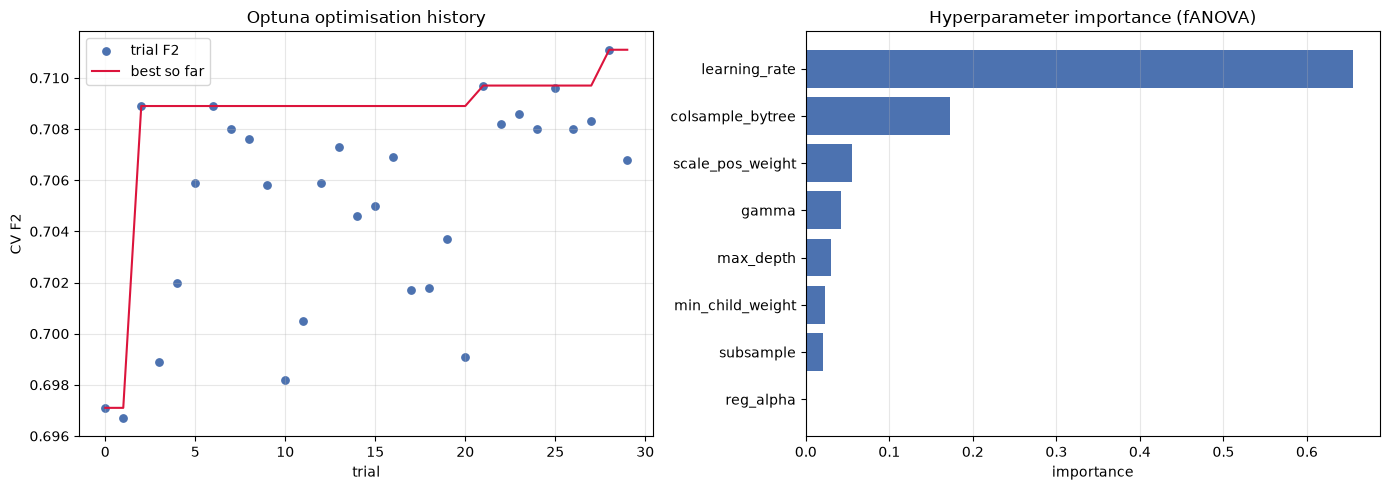

parameter importance:
learning_rate      0.6547
colsample_bytree   0.1732
scale_pos_weight   0.0552
gamma              0.0418
max_depth          0.0296
min_child_weight   0.0233
subsample          0.0202
reg_alpha          0.0019


In [18]:
section("6. OPTIMISATION HISTORY & PARAMETER IMPORTANCE")
history = pd.DataFrame({"trial": table["trial"], "cv_f2": table["cv_f2"]})
history["best_so_far"] = history["cv_f2"].cummax()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(history["trial"], history["cv_f2"], s=28, color="#4C72B0", label="trial F2")
axes[0].plot(history["trial"], history["best_so_far"], color="crimson", label="best so far")
axes[0].set_xlabel("trial")
axes[0].set_ylabel("CV F2")
axes[0].set_title("Optuna optimisation history")
axes[0].legend()
axes[0].grid(alpha=0.3)

try:
    importance = optuna.importance.get_param_importances(study)
    imp = pd.Series(importance).sort_values()
    axes[1].barh(imp.index, imp.values, color="#4C72B0")
    axes[1].set_title("Hyperparameter importance (fANOVA)")
    axes[1].set_xlabel("importance")
    axes[1].grid(alpha=0.3, axis="x")
except Exception as exc:  # noqa: BLE001
    importance = {}
    axes[1].text(0.05, 0.5, f"importance unavailable: {exc}")
    axes[1].set_axis_off()
plt.tight_layout()
plt.show()

if importance:
    print("parameter importance:")
    print(pd.Series(importance).round(4).to_string())

## 7. Best trial: cut-off, test evaluation, comparison

The cut-off comes from the pooled **out-of-fold** scores of the best parameters, so the test set
plays no part in choosing it. The test set is then scored once.


7. BEST TRIAL - OOF CUT-OFF AND HELD-OUT TEST SCORE
re-check CV best-F2      : 0.7111 (+/- 0.0160)
pooled OOF F2 at cut-off : 0.7074
operating cut-off (OOF)  : 0.2385 (mean fold cut-off 0.2549)
OOF PR-AUC 0.7005 | OOF ROC-AUC 0.8656

test ROC-AUC 0.8683 | test PR-AUC 0.7167

test comparison (each row at its own cut-off):
                                 label  threshold  recall  precision     f2  roc_auc  pr_auc
    baseline XGBoost (modelling.ipynb)     0.4510  0.7740     0.4869 0.6924   0.8620  0.7056
        previous run, PR-AUC objective     0.5223  0.7346     0.5368 0.6842   0.8669  0.7145
this run, F2 objective (reduced space)     0.2385  0.8403     0.4196 0.7000   0.8683  0.7167

cut-off sensitivity of this model on the test set:
 threshold  flagged_%  recall  precision     f2     f1
    0.1000    70.5500  0.9631     0.2778 0.6449 0.4312
    0.2000    45.9500  0.8698     0.3852 0.6949 0.5339
    0.2385    40.7500  0.8403     0.4196 0.7000 0.5597
    0.3000    32.9000  0.7789   

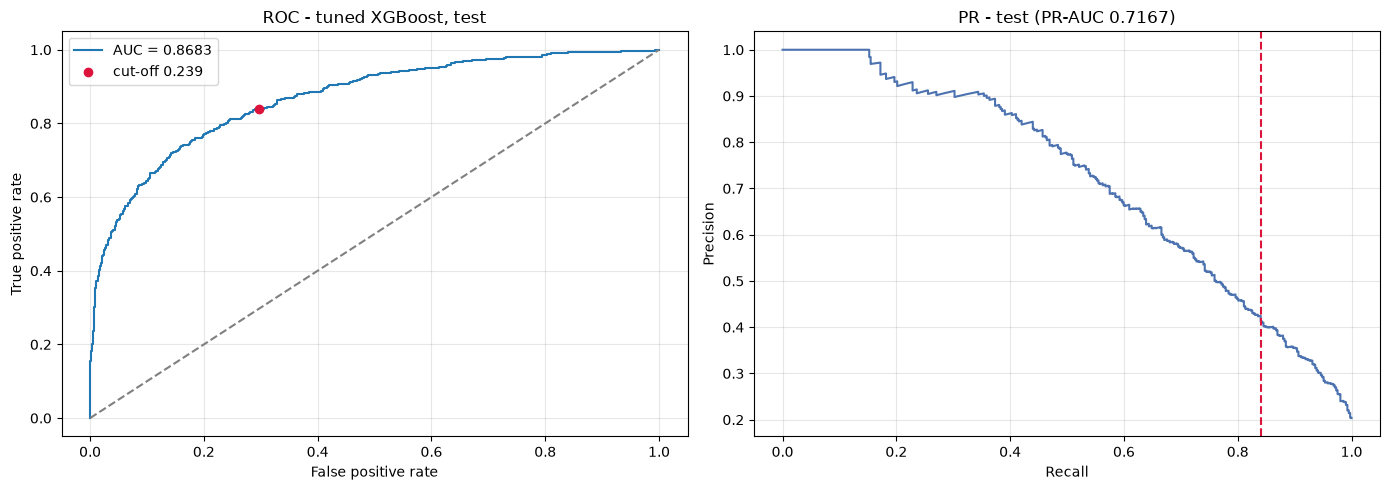

In [19]:
section("7. BEST TRIAL - OOF CUT-OFF AND HELD-OUT TEST SCORE")
best_params = full_params(dict(study.best_params))
cv_f2_mean, cv_f2_std, oof, fold_threshold = cross_validate(best_params, X_train, y_train)
f2_oof, THRESHOLD = best_fbeta(y_train, oof)

print(f"re-check CV best-F2      : {cv_f2_mean:.4f} (+/- {cv_f2_std:.4f})")
print(f"pooled OOF F2 at cut-off : {f2_oof:.4f}")
print(f"operating cut-off (OOF)  : {THRESHOLD:.4f} (mean fold cut-off {fold_threshold:.4f})")
print(f"OOF PR-AUC {average_precision_score(y_train, oof):.4f} | "
      f"OOF ROC-AUC {roc_auc_score(y_train, oof):.4f}")

final = XGBClassifier(**best_params, tree_method="hist", random_state=SEED, n_jobs=-1)
final.fit(X_train, y_train)
test_proba = final.predict_proba(X_test)[:, 1]

print()
print(f"test ROC-AUC {roc_auc_score(y_test, test_proba):.4f} | "
      f"test PR-AUC {average_precision_score(y_test, test_proba):.4f}")

tuned = metrics_at(y_test, test_proba, THRESHOLD)
compare = pd.DataFrame([
    {**BASELINE, "f2": round(fbeta_from_pr(BASELINE["precision"], BASELINE["recall"]), 4)},
    {**PRAUC_TUNED, "f2": round(fbeta_from_pr(PRAUC_TUNED["precision"], PRAUC_TUNED["recall"]), 4)},
    {"label": "this run, F2 objective (reduced space)", "threshold": tuned["threshold"],
     "roc_auc": round(roc_auc_score(y_test, test_proba), 4),
     "pr_auc": round(average_precision_score(y_test, test_proba), 4),
     "recall": tuned["recall"], "precision": tuned["precision"], "f2": tuned["f2"]},
])
print()
print("test comparison (each row at its own cut-off):")
print(compare[["label", "threshold", "recall", "precision", "f2", "roc_auc", "pr_auc"]]
      .to_string(index=False))

print()
print("cut-off sensitivity of this model on the test set:")
grid = [0.10, 0.20, 0.30, 0.40, 0.50, round(THRESHOLD, 4)]
print(pd.DataFrame([metrics_at(y_test, test_proba, t) for t in sorted(set(grid))]).to_string(index=False))

print()
print("confusion matrix at the operating cut-off:")
print(pd.DataFrame(confusion_matrix(y_test, (test_proba >= THRESHOLD).astype(int), labels=[0, 1]),
                   index=["actual: stayed", "actual: churned"],
                   columns=["pred: stayed", "pred: churned"]))
print()
print(classification_report(y_test, (test_proba >= THRESHOLD).astype(int), digits=3,
                            target_names=["stayed (0)", "churned (1)"]))

prec_c, rec_c, _ = precision_recall_curve(y_test, test_proba)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
f_t, t_t, _ = roc_curve(y_test, test_proba)
axes[0].plot(f_t, t_t, label=f"AUC = {roc_auc_score(y_test, test_proba):.4f}")
axes[0].plot([0, 1], [0, 1], "--", color="grey")
tuned_fpr = (confusion_matrix(y_test, (test_proba >= THRESHOLD).astype(int), labels=[0, 1])[0, 1]
             / (y_test == 0).sum())
operating_recall = metrics_at(y_test, test_proba, THRESHOLD)["recall"]
axes[0].scatter([tuned_fpr], [operating_recall], color="crimson", zorder=5,
                label=f"cut-off {THRESHOLD:.3f}")
axes[0].set_title("ROC - tuned XGBoost, test")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(rec_c, prec_c, color="#4C72B0")
axes[1].axvline(metrics_at(y_test, test_proba, THRESHOLD)["recall"], ls="--", color="crimson")
axes[1].set_title(f"PR - test (PR-AUC {average_precision_score(y_test, test_proba):.4f})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Feature importance of the tuned model


8. TUNED MODEL - FEATURE IMPORTANCE
NumOfProducts     0.2408
Age               0.1804
IsActiveMember    0.1461
Geo_Germany       0.0941
ZeroBalance       0.0585
Balance           0.0524
Geo_France        0.0397
Gender_Male       0.0358
Geo_Spain         0.0333
Gender_Female     0.0330
CreditScore       0.0244
EstimatedSalary   0.0239
Tenure            0.0193
HasCrCard         0.0184


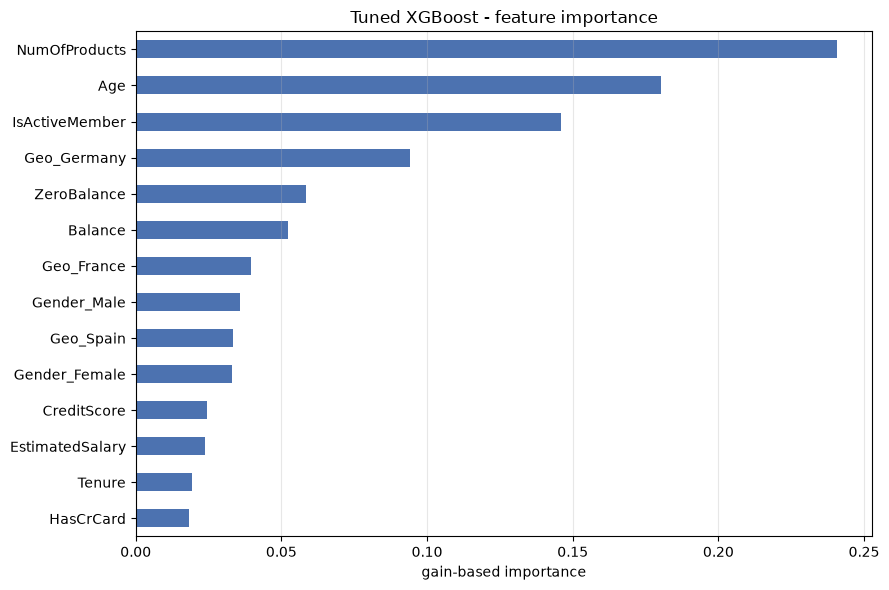

In [20]:
section("8. TUNED MODEL - FEATURE IMPORTANCE")
importance_df = pd.Series(final.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(importance_df.round(4).to_string())

fig, ax = plt.subplots(figsize=(9, 6))
importance_df.sort_values().plot.barh(ax=ax, color="#4C72B0")
ax.set_title("Tuned XGBoost - feature importance")
ax.set_xlabel("gain-based importance")
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

## 9. Summary

In [ ]:
section("9. SUMMARY")
print(f"objective                   : F{BETA:.0f} (recall weighted {BETA:.0f}x precision)")
print(f"search space                : {len(TUNED_PARAMS)} tuned + {len(FIXED_PARAMS)} fixed")
print(f"trials                      : {n_complete} complete / {len(study.trials)} run")
print(f"best trial                  : #{study.best_trial.number}")
print(f"best CV F2                  : {study.best_value:.4f} (+/- {cv_f2_std:.4f})")
print(f"test ROC-AUC / PR-AUC       : {roc_auc_score(y_test, test_proba):.4f} / "
      f"{average_precision_score(y_test, test_proba):.4f}")
print(f"operating cut-off (OOF F2)  : {THRESHOLD:.4f}")
print(f"test recall / precision / F2: {tuned['recall']:.4f} / {tuned['precision']:.4f} / {tuned['f2']:.4f}")
print(f"churners caught             : {int((test_proba >= THRESHOLD).astype(int)[y_test == 1].sum())}"
      f" of {int(y_test.sum())}")
print()
print("baseline caught 315/407 at precision 0.487; the PR-AUC run caught 299/407 at 0.537.")
print("F2 must trade precision for recall - check the comparison table above.")


9. SUMMARY
objective                   : F2 (recall weighted 2x precision)
search space                : 8 tuned + 5 fixed
trials                      : 30 complete / 30 run
best trial                  : #28
best CV F2                  : 0.7111 (+/- 0.0160)
test ROC-AUC / PR-AUC       : 0.8683 / 0.7167
operating cut-off (OOF F2)  : 0.2385
test recall / precision / F2: 0.8403 / 0.4196 / 0.7000
churners caught             : 342 of 407

baseline caught 315/407 at precision 0.487; the PR-AUC run caught 299/407 at 0.537.
F2 must trade precision for recall - check the comparison table above.


: 